# **UTS Graf Sains Data — Neo4j dan Rekomendasi**

## Konfigurasi koneksi dan uji koneksi

In [31]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from itertools import combinations
from sklearn.metrics.pairwise import cosine_similarity
from tqdm.auto import tqdm
from neo4j import GraphDatabase

URI = "neo4j:bolt//127.0.0.1:7687"
AUTH = ("neo4j", "grafsainsdatauts") 
DATABASE = "neo4j"

DATA_DIR = Path("data")
SOURCE_FILE = DATA_DIR / "events.csv"
P1_FILE = DATA_DIR / "events_p1.csv"
P2_FILE = DATA_DIR / "events_p2.csv"
DATA_DIR.mkdir(parents=True, exist_ok=True)

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    with driver.session(database=DATABASE) as session:
        print("Koneksi Neo4j berhasil.")


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_32888\2105267625.py:22: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Koneksi Neo4j berhasil.


In [32]:
# def delete_nodes_in_batches(session, label, batch_size=5000):
#     query = f"""
#     MATCH (n:{label})
#     WITH n LIMIT $batch_size
#     DETACH DELETE n
#     RETURN count(n) AS deleted
#     """
#     while True:
#         result = session.run(query, batch_size=batch_size)
#         summary = result.single()
#         deleted_count = summary["deleted"] if summary else 0
#         if deleted_count == 0:
#             break

# with GraphDatabase.driver(URI, auth=AUTH) as driver:
#     with driver.session(database=DATABASE) as session:
#         for label in ["Person", "Visitor", "Item"]:
#             delete_nodes_in_batches(session, label)
#         print("Data kerja telah dihapus secara bertahap.")

## Tugas pendahuluan: node dan relasi pertemanan

In [33]:
def add_friend(session, name, friend_name):
    session.run(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name,
    )

def print_friends(session, name):
    result = session.run(
        "MATCH (a:Person)-[:KNOWS]->(friend) "
        "WHERE a.name = $name "
        "RETURN friend.name AS friend_name ORDER BY friend_name",
        name=name,
    )
    for record in result:
        print(record["friend_name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        add_friend(session, "Arthur", "Guinevere")
        add_friend(session, "Arthur", "Lancelot")
        add_friend(session, "Arthur", "Merlin")
        print_friends(session, "Arthur")


Guinevere
Lancelot
Merlin


# Soal Pendahuluan

## 1. Apa nama database yang digunakan pada tutorial ini?

**Jawaban:** Neo4j.

## 2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan untuk mengakses database lain dalam satu instance.

**Jawaban:** Database dapat diakses menggunakan bahasa query **Cypher**, termasuk perintah DDL dan DML, seperti:

- `CREATE`: membuat node, relasi, atau struktur data.
- `MATCH`: mencari node dan relasi berdasarkan pola graf.
- `MERGE`: mencari data yang sesuai atau membuatnya jika belum ada.
- `SET`: menambahkan atau memperbarui properti.
- `DELETE`: menghapus node atau relasi.
- `DROP DATABASE`: menghapus database.

Untuk mengakses database tertentu dalam satu instance Neo4j, database dapat dipilih melalui parameter `database` pada `driver.session(database="nama_database")` atau menggunakan perintah `:use nama_database` pada Neo4j Browser, sesuai hak akses yang tersedia.

## 3. Apa jenis graf pertemanan yang telah dibuat?

**Jawaban:** Graf yang dibuat merupakan **graf berarah (*directed graph*)**, sederhana, tak berbobot, dan homogen. Graf menggunakan satu label node, yaitu `Person`, dan satu jenis relasi, yaitu `KNOWS`.

Arthur menjadi pusat graf dengan tiga relasi keluar menuju Guinevere, Lancelot, dan Merlin. Dengan demikian, *out-degree* Arthur adalah 3, sedangkan setiap temannya memiliki *in-degree* 1 dari Arthur. Graf ini tidak memiliki siklus berdasarkan relasi yang dibuat.

Perintah `MERGE` digunakan untuk mencegah pembuatan node dan relasi yang sama secara berulang. Meskipun hubungan pertemanan biasanya bersifat dua arah, kode tersebut hanya membuat relasi satu arah, yaitu dari Arthur menuju masing-masing temannya.

## Wrangling: filter P1 dan P2

In [34]:
# Batas akhir eksklusif: seluruh hari terakhir tetap masuk.
# P1: 2015-05-31 sampai 2015-07-31
# P2: 2015-08-09 sampai 2015-08-24
p1_start = int(pd.Timestamp("2015-05-31", tz="UTC").timestamp() * 1000)
p1_end = int(pd.Timestamp("2015-08-01", tz="UTC").timestamp() * 1000)
p2_start = int(pd.Timestamp("2015-08-09", tz="UTC").timestamp() * 1000)
p2_end = int(pd.Timestamp("2015-08-25", tz="UTC").timestamp() * 1000)

if not SOURCE_FILE.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {SOURCE_FILE}. Letakkan events.csv di folder data.")

for output in [P1_FILE, P2_FILE]:
    if output.exists():
        output.unlink()

p1_count = p2_count = 0
for chunk in pd.read_csv(SOURCE_FILE, chunksize=200_000):
    chunk["timestamp"] = pd.to_numeric(chunk["timestamp"], errors="coerce")
    chunk = chunk.dropna(subset=["timestamp"])
    p1 = chunk[(chunk["timestamp"] >= p1_start) & (chunk["timestamp"] < p1_end)]
    p2 = chunk[(chunk["timestamp"] >= p2_start) & (chunk["timestamp"] < p2_end)]
    if not p1.empty:
        p1.to_csv(P1_FILE, mode="a", index=False, header=(p1_count == 0))
        p1_count += len(p1)
    if not p2.empty:
        p2.to_csv(P2_FILE, mode="a", index=False, header=(p2_count == 0))
        p2_count += len(p2)

print("Jumlah baris P1:", p1_count)
print("Jumlah baris P2:", p2_count)
print("File P1:", P1_FILE)
print("File P2:", P2_FILE)


Jumlah baris P1: 1324774
Jumlah baris P2: 279544
File P1: data\events_p1.csv
File P2: data\events_p2.csv


## Impor batch P1 ke Neo4j

In [35]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(session, batch):
    query = '''
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    '''
    session.run(query, batch=batch)

if not P1_FILE.exists():
    raise FileNotFoundError("events_p1.csv belum ada. Jalankan bagian wrangling.")

batch_size = 5000
usecols = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
total_rows = sum(len(c) for c in pd.read_csv(P1_FILE, usecols=usecols, chunksize=batch_size))
total_chunks = (total_rows + batch_size - 1) // batch_size

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    with driver.session(database=DATABASE) as session:
        create_constraints(session)
        query_delete = """
        MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()
        WITH r
        LIMIT $batch_size
        DELETE r
        RETURN count(*) AS deleted
        """

        total_deleted = 0

        while True:
            result = session.run(query_delete, batch_size=1000)
            deleted = result.single()["deleted"]

            total_deleted += deleted

            if deleted == 0:
                break

        print(f"Total relasi lama yang dihapus: {total_deleted}")
        for chunk in tqdm(pd.read_csv(P1_FILE, usecols=usecols, chunksize=batch_size),
                          total=total_chunks, desc="Mengimpor batch P1"):
            chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
            for col in ["timestamp", "visitorid", "itemid"]:
                chunk[col] = pd.to_numeric(chunk[col], errors="coerce")
            chunk = chunk.dropna(subset=["timestamp", "visitorid", "itemid", "event"])
            records = chunk.to_dict(orient="records")
            if records:
                import_batch(session, records)

print("Impor P1 selesai.")


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_32888\1525712736.py:36: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Total relasi lama yang dihapus: 1324774


Mengimpor batch P1: 100%|██████████| 265/265 [03:42<00:00,  1.19it/s]

Impor P1 selesai.


## EDA: komposisi subgraph dengan Python API

In [36]:
queries = {
    "Jumlah Visitor": "MATCH (v:Visitor) RETURN count(v) AS jumlah",
    "Jumlah Item": "MATCH (i:Item) RETURN count(i) AS jumlah",
    "Jumlah VIEWED": "MATCH ()-[r:VIEWED]->() RETURN count(r) AS jumlah",
    "Jumlah ADDED_TO_CART": "MATCH ()-[r:ADDED_TO_CART]->() RETURN count(r) AS jumlah",
    "Jumlah BOUGHT": "MATCH ()-[r:BOUGHT]->() RETURN count(r) AS jumlah",
}
eda_results = {}
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        for label, query in queries.items():
            value = session.run(query).single()["jumlah"]
            eda_results[label] = value
            print(f"{label}: {value}")

print("MATCH mencari pola graf; count() menghitung node/relasi; RETURN mengembalikan hasil.")


Jumlah Visitor: 684227
Jumlah Item: 171126
Jumlah VIEWED: 1281023
Jumlah ADDED_TO_CART: 32807
Jumlah BOUGHT: 10944
MATCH mencari pola graf; count() menghitung node/relasi; RETURN mengembalikan hasil.


## VSM Visitor dan proyeksi graf

In [37]:
query = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH v, count(r) AS total
ORDER BY total DESC
LIMIT 200
MATCH (v)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN
    v.visitorId AS visitor_id,
    i.itemId AS item_id,
    count(r) AS interaction_count
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        records = [dict(record) for record in session.run(query)]

df = pd.DataFrame(records)

if df.empty:
    raise ValueError(
        "Data interaksi Visitor-Item kosong. Periksa data dan koneksi Neo4j."
    )

df = (
    df.groupby(["visitor_id", "item_id"], as_index=False)
      ["interaction_count"].sum()
)

# VSM Visitor: baris = Visitor, kolom = Item
X_visitor = pd.crosstab(
    df["visitor_id"],
    df["item_id"],
    values=df["interaction_count"],
    aggfunc="sum"
).fillna(0)

# VSM Item: baris = Item, kolom = Visitor
X_item = X_visitor.T

print("Data berhasil disiapkan.")
print("VSM Visitor:", X_visitor.shape)
print("VSM Item:", X_item.shape)

Data berhasil disiapkan.
VSM Visitor: (200, 22479)
VSM Item: (22479, 200)


In [38]:
G_bipartite = nx.Graph()

for row in df.itertuples(index=False):
    user = f"User_{row.visitor_id}"
    item = f"Item_{row.item_id}"

    G_bipartite.add_node(user, node_type="User")
    G_bipartite.add_node(item, node_type="Item")
    G_bipartite.add_edge(
        user, item,
        weight=row.interaction_count
    )

# Menentukan kelompok simpul
user_nodes = [f"User_{u}" for u in X_visitor.index]
item_nodes = [f"Item_{i}" for i in X_item.index]

print("Graf bipartit berhasil dibuat.")
print("Jumlah simpul:", G_bipartite.number_of_nodes())
print("Jumlah edge:", G_bipartite.number_of_edges())


Graf bipartit berhasil dibuat.
Jumlah simpul: 22679
Jumlah edge: 43319


=== KARAKTERISTIK VSM USER ===
Dimensi: 2
Shape: (200, 22479)
Jumlah User: 200
Jumlah Item: 22479
Jumlah nilai nonzero: 43319

Contoh VSM User:


item_id,15,16,26,42,66,119,124,147,152,155,...,466710,466712,466736,466740,466747,466759,466783,466796,466861,466864
visitor_id,,,,,,,,,,,,,,,,,,,,,
6170,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6958,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9535,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12579,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
21395,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



=== PROYEKSI USER ===
Jumlah simpul: 200
Jumlah edge: 9202


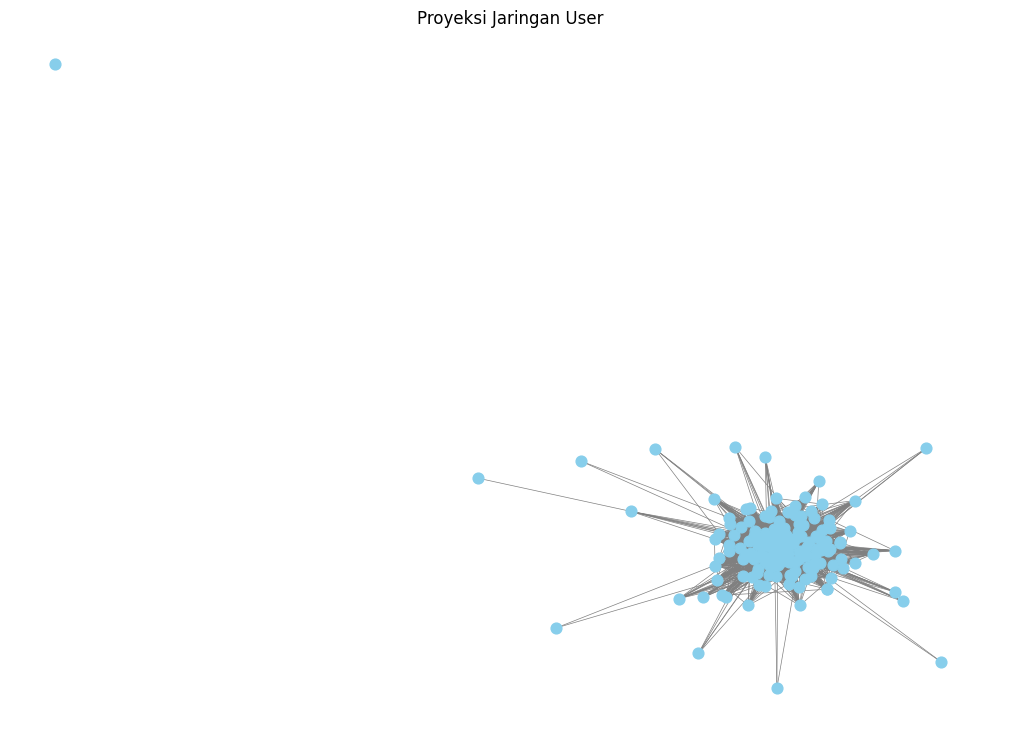

In [39]:
X_user = X_visitor.copy()

print("=== KARAKTERISTIK VSM USER ===")
print("Dimensi:", X_user.ndim)
print("Shape:", X_user.shape)
print("Jumlah User:", X_user.shape[0])
print("Jumlah Item:", X_user.shape[1])
print("Jumlah nilai nonzero:", (X_user.to_numpy() != 0).sum())

print("\nContoh VSM User:")
display(X_user.head())

# Proyeksi graf User:
# Dua User terhubung jika berinteraksi dengan Item yang sama
G_user_projection = nx.bipartite.weighted_projected_graph(
    G_bipartite, user_nodes
)

print("\n=== PROYEKSI USER ===")
print("Jumlah simpul:", G_user_projection.number_of_nodes())
print("Jumlah edge:", G_user_projection.number_of_edges())

# Visualisasi
plt.figure(figsize=(10, 7))

# Batasi simpul yang digambar, bukan data VSM
nodes = list(G_user_projection.nodes())[:500]
G_user_plot = G_user_projection.subgraph(nodes)

pos = nx.spring_layout(G_user_plot, seed=42, iterations=20)

nx.draw(
    G_user_plot,
    pos,
    with_labels=False,
    node_color="skyblue",
    node_size=60,
    edge_color="gray",
    width=0.5
)

plt.title("Proyeksi Jaringan User")
plt.axis("off")
plt.show()


## VSM Item dan proyeksi graf

=== KARAKTERISTIK VSM ITEM ===
Dimensi: 2
Shape: (22479, 200)
Jumlah Item: 22479
Jumlah User: 200
Jumlah nilai nonzero: 43319

Contoh VSM Item:


visitor_id,6170,6958,9535,12579,21395,33604,38015,48820,54791,57905,...,1336835,1343677,1348163,1356496,1357576,1376763,1381830,1384823,1385073,1403769
item_id,,,,,,,,,,,,,,,,,,,,,
15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
42,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
66,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Rata-rata interaksi per Item: 3.340406601717158
Interaksi terbanyak: 357.0
Interaksi tersedikit: 1.0

=== PROYEKSI ITEM ===
Jumlah Item: 300
Jumlah edge: 26620


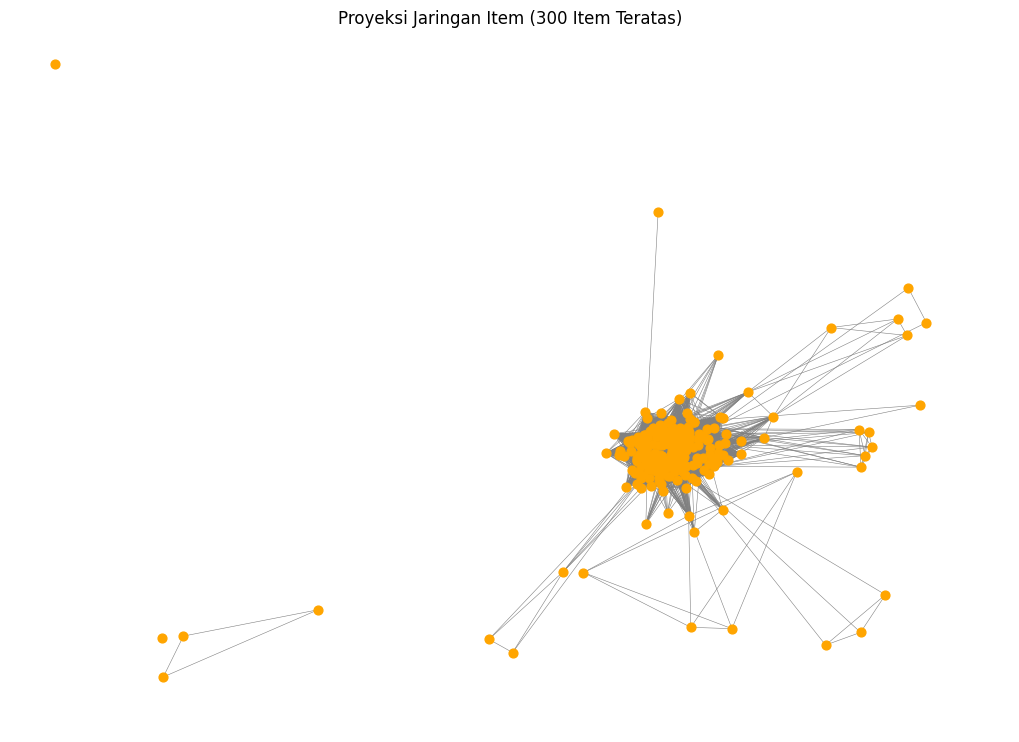

In [40]:
X_item = X_visitor.T

print("=== KARAKTERISTIK VSM ITEM ===")
print("Dimensi:", X_item.ndim)
print("Shape:", X_item.shape)
print("Jumlah Item:", X_item.shape[0])
print("Jumlah User:", X_item.shape[1])
print("Jumlah nilai nonzero:", (X_item.to_numpy() != 0).sum())

print("\nContoh VSM Item:")
display(X_item.head())

# Statistik interaksi Item
jumlah_interaksi_item = X_item.sum(axis=1)

print("\nRata-rata interaksi per Item:",
      jumlah_interaksi_item.mean())
print("Interaksi terbanyak:", jumlah_interaksi_item.max())
print("Interaksi tersedikit:", jumlah_interaksi_item.min())

# Proyeksi graf Item yang lebih ringan
# Pilih 300 Item dengan interaksi terbanyak
top_items = jumlah_interaksi_item.nlargest(300).index
top_item_nodes = [f"Item_{i}" for i in top_items]

# Gunakan subgraf bipartit untuk Item terpilih
G_bipartite_subset = G_bipartite.subgraph(
    user_nodes + top_item_nodes
)

G_item_projection = nx.bipartite.weighted_projected_graph(
    G_bipartite_subset,
    top_item_nodes
)

print("\n=== PROYEKSI ITEM ===")
print("Jumlah Item:", G_item_projection.number_of_nodes())
print("Jumlah edge:", G_item_projection.number_of_edges())

# Visualisasi jaringan Item
plt.figure(figsize=(10, 7))

pos = nx.spring_layout(
    G_item_projection,
    seed=42,
    iterations=10
)

nx.draw(
    G_item_projection,
    pos,
    with_labels=False,
    node_color="orange",
    node_size=40,
    edge_color="gray",
    width=0.4
)

plt.title("Proyeksi Jaringan Item (300 Item Teratas)")
plt.axis("off")
plt.show()


## Membandingkan proyeksi

Visitor-projection membantu menemukan pengunjung dengan pola interaksi serupa; item-projection membantu menemukan produk yang berinteraksi dengan pengunjung yang sama. Gunakan angka hasil eksekusi untuk membahas dimensi matriks, jumlah node/edge, dan efisiensi. Tidak ada proyeksi yang otomatis selalu lebih baik.

In [41]:
MAX_USER = 100
MAX_ITEM = 100

top_users = X_visitor.sum(axis=1).nlargest(MAX_USER).index
top_items = X_visitor.loc[top_users].sum(axis=0).nlargest(MAX_ITEM).index

X_sample = X_visitor.loc[top_users, top_items]

# Buat graf bipartit
G_sample = nx.Graph()

user_nodes_sample = [f"User_{u}" for u in X_sample.index]
item_nodes_sample = [f"Item_{i}" for i in X_sample.columns]

# PENTING: tambahkan semua simpul terlebih dahulu
G_sample.add_nodes_from(user_nodes_sample, bipartite=0)
G_sample.add_nodes_from(item_nodes_sample, bipartite=1)

# Tambahkan edge untuk pasangan yang memiliki interaksi
for user in X_sample.index:
    for item in X_sample.columns:
        weight = X_sample.loc[user, item]

        if weight > 0:
            G_sample.add_edge(
                f"User_{user}",
                f"Item_{item}",
                weight=float(weight)
            )

# Proyeksi User
start = time.perf_counter()
G_user_projection = nx.bipartite.weighted_projected_graph(
    G_sample, user_nodes_sample
)
waktu_user = time.perf_counter() - start

# Proyeksi Item
start = time.perf_counter()
G_item_projection = nx.bipartite.weighted_projected_graph(
    G_sample, item_nodes_sample
)
waktu_item = time.perf_counter() - start

# Ringkasan karakteristik graf
def ringkasan_graf(nama, G, waktu):
    n = G.number_of_nodes()
    e = G.number_of_edges()

    return {
        "Proyeksi": nama,
        "Jumlah simpul": n,
        "Jumlah edge": e,
        "Kepadatan graf": nx.density(G) if n > 1 else 0,
        "Rata-rata derajat": 2 * e / n if n > 0 else 0,
        "Waktu (detik)": waktu
    }

hasil_perbandingan = pd.DataFrame([
    ringkasan_graf("User", G_user_projection, waktu_user),
    ringkasan_graf("Item", G_item_projection, waktu_item)
])

display(hasil_perbandingan.round(5))


,Proyeksi,Jumlah simpul,Jumlah edge,Kepadatan graf,Rata-rata derajat,Waktu (detik)
0,User,100,2741,0.55374,54.82,0.04773
1,Item,100,3474,0.70182,69.48,0.06366


## Similarity Visitor, lima pasangan teratas, dan update Neo4j

In [42]:
query_all = '''
MATCH (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN DISTINCT v.visitorId AS visitor_id, i.itemId AS item_id
'''
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        records = [dict(r) for r in session.run(query_all)]

visitor_items = {}
for row in records:
    visitor_items.setdefault(row["visitor_id"], set()).add(row["item_id"])

selected_for_similarity = sorted(visitor_items, key=lambda v: len(visitor_items[v]), reverse=True)[:300]
similarity_pairs = []
for a, b in combinations(selected_for_similarity, 2):
    union = visitor_items[a] | visitor_items[b]
    if union:
        score = len(visitor_items[a] & visitor_items[b]) / len(union)  # Jaccard
        if score > 0:
            similarity_pairs.append({"visitor_a": a, "visitor_b": b, "similarity": float(score)})
similarity_pairs.sort(key=lambda x: x["similarity"], reverse=True)
top5_pairs = similarity_pairs[:5]
print("Lima pasangan similarity tertinggi (Jaccard):")
display(pd.DataFrame(top5_pairs))


Lima pasangan similarity tertinggi (Jaccard):


,visitor_a,visitor_b,similarity
0,317355,360921,0.213542
1,1119917,917504,0.169935
2,518659,1000306,0.155056
3,856874,590943,0.146739
4,1119917,468309,0.138264


### Cypher: lima pasangan similarity tertinggi

In [43]:
query_top_similarity = '''
MATCH (a:Visitor)-[r:SIMILAR_TO]-(b:Visitor)
WHERE a.visitorId < b.visitorId
RETURN
    a.visitorId AS visitor_a,
    b.visitorId AS visitor_b,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
'''

print(query_top_similarity)



MATCH (a:Visitor)-[r:SIMILAR_TO]-(b:Visitor)
WHERE a.visitorId < b.visitorId
RETURN
    a.visitorId AS visitor_a,
    b.visitorId AS visitor_b,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5



### Graf sebelum similarity

Graf sebelum similarity — node: 967 | edge: 1000


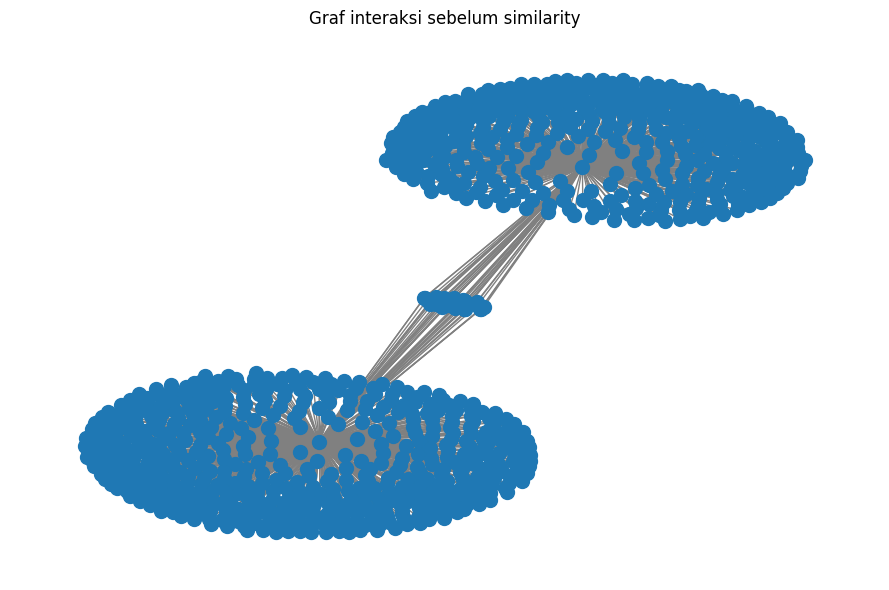

In [44]:
# Graf interaksi Visitor-Item sederhana sebelum SIMILAR_TO ditambahkan.
before_graph = nx.Graph()
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        before_records = [dict(r) for r in session.run(
            '''
            MATCH (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
            WHERE v.visitorId IN $visitors
            RETURN DISTINCT v.visitorId AS visitor_id, i.itemId AS item_id LIMIT 1000
            ''', visitors=selected_for_similarity[:30]
        )]
for row in before_records:
    before_graph.add_edge(row["visitor_id"], row["item_id"])
print("Graf sebelum similarity — node:", before_graph.number_of_nodes(), "| edge:", before_graph.number_of_edges())
plt.figure(figsize=(9, 6))
nx.draw_networkx(before_graph, nx.spring_layout(before_graph, seed=42),
                 with_labels=False, node_size=100, edge_color="gray")
plt.title("Graf interaksi sebelum similarity")
plt.axis("off"); plt.tight_layout(); plt.show()


### 10c. Simpan hingga 1.000 pasangan dan jalankan query

In [45]:
top_pairs_to_save = similarity_pairs[:1000]
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        session.run("MATCH ()-[r:SIMILAR_TO]-() DELETE r")
        if top_pairs_to_save:
            session.run(
                '''
                UNWIND $pairs AS pair
                MATCH (a:Visitor {visitorId: pair.visitor_a})
                MATCH (b:Visitor {visitorId: pair.visitor_b})
                MERGE (a)-[r:SIMILAR_TO]-(b)
                SET r.similarity = pair.similarity
                ''',
                pairs=top_pairs_to_save,
            )
        saved_count = session.run(
            """
            MATCH ()-[r:SIMILAR_TO]-()
            RETURN count(DISTINCT r) AS jumlah
            """
        ).single()["jumlah"]

        top5_db = [dict(r) for r in session.run(query_top_similarity)]
print("Relasi SIMILAR_TO tersimpan:", saved_count)
display(pd.DataFrame(top5_db))


Relasi SIMILAR_TO tersimpan: 1000


,visitor_a,visitor_b,similarity
0,317355,360921,0.213542
1,917504,1119917,0.169935
2,518659,1000306,0.155056
3,590943,856874,0.146739
4,468309,1119917,0.138264


### Graf setelah similarity

Graf similarity setelah update — node: 56 | edge: 50


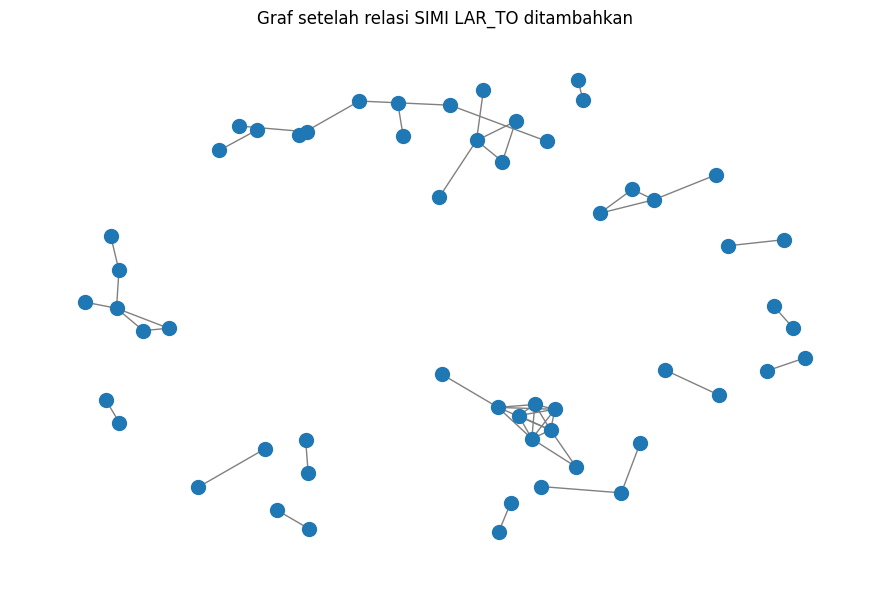

In [46]:

after_graph = nx.Graph()
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        after_records = [dict(r) for r in session.run(
            '''
            MATCH (a:Visitor)-[r:SIMILAR_TO]-(b:Visitor)
            RETURN a.visitorId AS visitor_a, b.visitorId AS visitor_b,
                   r.similarity AS similarity
            ORDER BY similarity DESC LIMIT 100
            '''
        )]
for row in after_records:
    after_graph.add_edge(row["visitor_a"], row["visitor_b"], weight=row["similarity"])
print("Graf similarity setelah update — node:", after_graph.number_of_nodes(), "| edge:", after_graph.number_of_edges())
plt.figure(figsize=(9, 6))
nx.draw_networkx(after_graph, nx.spring_layout(after_graph, seed=42),
                 with_labels=False, node_size=100, edge_color="gray")
plt.title("Graf setelah relasi SIMI LAR_TO ditambahkan")
plt.axis("off"); plt.tight_layout(); plt.show()


## Analytics: KNN dengan k=5, rekomendasi tiga item, Hit@5 dan NDCG@5

User dipilih secara acak tetapi dapat direproduksi menggunakan seed tetap. P1 menjadi training, P2 menjadi testing. Hasil evaluasi bisa bernilai 0 jika rekomendasi tidak cocok dengan item P2; jangan memilih user berdasarkan hasil evaluasi karena itu membuat evaluasi bias.

In [47]:
train = pd.read_csv(P1_FILE)
test = pd.read_csv(P2_FILE)

# Periksa struktur kolom
print("Kolom train:", train.columns.tolist())
print("Kolom test:", test.columns.tolist())

display(train.head())

Kolom train: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
Kolom test: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [48]:
# # Ambil interaksi user-item dari P1
# interactions = (
#     train.groupby(["visitorid", "itemid"])
#     .size()
#     .reset_index(name="interaction")
# )

# # Buat pemetaan user dan item menjadi indeks angka
# user_ids = interactions["visitorid"].unique()
# item_ids = interactions["itemid"].unique()

# user_to_idx = {user_id: idx for idx, user_id in enumerate(user_ids)}
# item_to_idx = {item_id: idx for idx, item_id in enumerate(item_ids)}

# # Ubah ID menjadi indeks matriks
# row = interactions["visitorid"].map(user_to_idx).to_numpy()
# col = interactions["itemid"].map(item_to_idx).to_numpy()
# data = interactions["interaction"].to_numpy(dtype=np.float32)

# # Buat matriks sparse
# user_item_matrix = csr_matrix(
#     (data, (row, col)),
#     shape=(len(user_ids), len(item_ids)),
#     dtype=np.float32
# )

# print("Ukuran matriks:", user_item_matrix.shape)
# print("Jumlah user:", len(user_ids))
# print("Jumlah item:", len(item_ids))
# print("Jumlah interaksi unik:", user_item_matrix.nnz)

In [49]:
start = time.time()
rng = np.random.default_rng(42)

# ==========================================
# 1. PERSIAPAN DATA
# ==========================================
train = train.rename(columns={
    "visitorid": "visitor_id",
    "itemid": "item_id"
}).copy()

test = test.rename(columns={
    "visitorid": "visitor_id",
    "itemid": "item_id"
}).copy()

assert {"visitor_id", "item_id"}.issubset(train.columns)
assert {"visitor_id", "item_id"}.issubset(test.columns)

# Hitung frekuensi interaksi setiap user-item dari TRAIN saja
interactions = (
    train.groupby(["visitor_id", "item_id"])
    .size()
    .reset_index(name="interaction")
)

# Batas komputasi untuk percobaan yang lebih cepat
MAX_CANDIDATE_USERS = 3000
MAX_EVAL_USERS = 100
K = 5
TOP_N = 5

# Ambil sampel user yang memiliki minimal 2 interaksi di train
user_counts = interactions.groupby("visitor_id").size()
active_users = user_counts[user_counts >= 2].index.to_numpy()

if len(active_users) < 2:
    raise ValueError("Jumlah user aktif di train tidak mencukupi.")

candidate_users = rng.choice(
    active_users,
    size=min(MAX_CANDIDATE_USERS, len(active_users)),
    replace=False
)

candidate_set = set(candidate_users)

# Gunakan hanya interaksi train dari kandidat user
interactions = interactions[
    interactions["visitor_id"].isin(candidate_set)
].copy()

user_ids = pd.Index(candidate_users)
item_ids = pd.Index(interactions["item_id"].unique())

user_to_idx = {u: i for i, u in enumerate(user_ids)}
item_to_idx = {item: i for i, item in enumerate(item_ids)}

rows = interactions["visitor_id"].map(user_to_idx).to_numpy()
cols = interactions["item_id"].map(item_to_idx).to_numpy()
values = interactions["interaction"].to_numpy(dtype=np.float32)

# Matriks sparse: dibentuk dari TRAIN, bukan TEST
user_item_matrix = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.float32
)

print("Jumlah kandidat user:", len(user_ids))
print("Jumlah item:", len(item_ids))
print("Jumlah interaksi:", user_item_matrix.nnz)

# ==========================================
# 2. SIAPKAN RELEVANSI DARI TEST
# ==========================================
# Hanya evaluasi item yang tersedia di katalog train.
# Item yang sudah dilihat saat train tidak dihitung relevan.
test_subset = test[
    test["visitor_id"].isin(candidate_set)
    & test["item_id"].isin(item_to_idx)
]

test_relevant = {}

for user, group in test_subset.groupby("visitor_id"):
    uidx = user_to_idx[user]
    seen = set(user_item_matrix[uidx].indices)

    relevant = {
        item_to_idx[item]
        for item in group["item_id"].unique()
        if item_to_idx[item] not in seen
    }

    if relevant:
        test_relevant[uidx] = relevant

eligible = np.array(list(test_relevant.keys()))

if len(eligible) == 0:
    raise ValueError(
        "Tidak ada user evaluasi yang memenuhi syarat. "
        "Periksa pembagian P1/P2 dan ketersediaan item."
    )

eval_users = rng.choice(
    eligible,
    size=min(MAX_EVAL_USERS, len(eligible)),
    replace=False
)

print("Jumlah user evaluasi:", len(eval_users))

# ==========================================
# 3. FIT KNN PADA DATA TRAIN
# ==========================================
knn = NearestNeighbors(
    n_neighbors=min(K + 1, len(user_ids)),
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

knn.fit(user_item_matrix)

print("KNN selesai fit.")

# ==========================================
# 4. SKOR POPULARITAS DARI TRAIN
# ==========================================
popularity = np.asarray(
    user_item_matrix.sum(axis=0)
).ravel().astype(np.float32)

# ==========================================
# 5. REKOMENDASI DAN EVALUASI
# ==========================================
results = []

for uidx in eval_users:
    # Cari tetangga untuk user evaluasi ini saja
    distances, neighbors = knn.kneighbors(
        user_item_matrix[uidx],
        return_distance=True
    )

    neighbor_ids = []
    similarities = []

    for neighbor, distance in zip(neighbors[0], distances[0]):
        if neighbor == uidx:
            continue

        similarity = max(0.0, 1.0 - float(distance))

        if similarity > 0:
            neighbor_ids.append(neighbor)
            similarities.append(similarity)

        if len(neighbor_ids) >= K:
            break

    # Skor rekomendasi berdasarkan interaksi tetangga
    if neighbor_ids:
        scores = np.asarray(
            user_item_matrix[neighbor_ids].T.dot(
                np.asarray(similarities, dtype=np.float32)
            )
        ).ravel()
    else:
        scores = np.zeros(len(item_ids), dtype=np.float32)

    # Item yang sudah dilihat tidak boleh direkomendasikan
    seen = user_item_matrix[uidx].indices
    scores[seen] = -np.inf

    # Fallback: popularitas item dari TRAIN
    if not np.any(scores > 0):
        scores = popularity.copy()
        scores[seen] = -np.inf

    # Urutkan berdasarkan skor tertinggi
    top_indices = np.argsort(scores)[::-1][:TOP_N]
    top_indices = [
        int(i) for i in top_indices if np.isfinite(scores[i])
    ]

    relevant = test_relevant[uidx]

    # Hit@5
    relevance_at_k = [
        int(item in relevant) for item in top_indices
    ]
    hit_at_5 = int(any(relevance_at_k))

    # NDCG@5 dengan relevansi biner dari TEST
    dcg = sum(
        rel / np.log2(rank + 2)
        for rank, rel in enumerate(relevance_at_k)
    )

    ideal_count = min(len(relevant), TOP_N)
    idcg = sum(
        1 / np.log2(rank + 2)
        for rank in range(ideal_count)
    )

    ndcg_at_5 = dcg / idcg if idcg > 0 else 0.0

    results.append({
        "visitor_id": user_ids[uidx],
        "recommendations": [
            item_ids[i] for i in top_indices
        ],
        "Hit@5": hit_at_5,
        "NDCG@5": ndcg_at_5
    })

# ==========================================
# 6. HASIL
# ==========================================
hasil = pd.DataFrame(results)

print("\n===== HASIL EVALUASI KNN =====")
print("User dievaluasi:", len(hasil))
print(f"Hit@5  : {hasil['Hit@5'].mean():.4f}")
print(f"NDCG@5 : {hasil['NDCG@5'].mean():.4f}")
print(f"Waktu total: {time.time() - start:.2f} detik")

display(hasil.head(10))


Jumlah kandidat user: 3000
Jumlah item: 8910
Jumlah interaksi: 10908
Jumlah user evaluasi: 26
KNN selesai fit.

===== HASIL EVALUASI KNN =====
User dievaluasi: 26
Hit@5  : 0.0000
NDCG@5 : 0.0000
Waktu total: 2.77 detik


,visitor_id,recommendations,Hit@5,NDCG@5
0,428868,"[248450, 344723, 259571, 20968, 23477]",0,0.0
1,207113,"[415610, 413246, 452722, 396362, 332721]",0,0.0
2,27017,"[161703, 24734, 312867, 244636, 335975]",0,0.0
3,284876,"[1115, 15583, 115258, 458271, 108021]",0,0.0
4,686800,"[447632, 233538, 367624, 13823, 75994]",0,0.0
5,985080,"[161703, 24734, 244636, 312867, 278679]",0,0.0
6,1067969,"[303828, 58638, 1115, 15583, 115258]",0,0.0
7,863977,"[161703, 24734, 244636, 312867, 361554]",0,0.0
8,485310,"[161703, 24734, 312867, 244636, 361554]",0,0.0
9,544845,"[161703, 24734, 312867, 244636, 361554]",0,0.0


In [50]:

# Tampilkan rekomendasi aktual dari user evaluasi pertama
if not hasil.empty:
    rekomendasi_pertama = hasil.iloc[0]

    print("User yang dipilih:", rekomendasi_pertama["visitor_id"])
    print("\nTiga item rekomendasi teratas:")

    for peringkat, item_id in enumerate(
        rekomendasi_pertama["recommendations"][:3],
        start=1
    ):
        print(f"{peringkat}. Item {item_id}")

    print("\nEvaluasi user tersebut:")
    print("Hit@5 :", rekomendasi_pertama["Hit@5"])
    print("NDCG@5:", round(rekomendasi_pertama["NDCG@5"], 4))
else:
    print("Belum ada hasil rekomendasi.")


User yang dipilih: 428868

Tiga item rekomendasi teratas:
1. Item 248450
2. Item 344723
3. Item 259571

Evaluasi user tersebut:
Hit@5 : 0
NDCG@5: 0.0



# A. Wrangling dan Eksplorasi Graf

## 1. Menentukan Dua Periode Waktu

**Jawaban:**

Periode waktu yang digunakan untuk membagi data interaksi adalah:

- **P1 (Training):** 31 Mei 2015 sampai 31 Juli 2015.
- **P2 (Testing):** 9 Agustus 2015 sampai 24 Agustus 2015.

Batas akhir dibuat eksklusif, yaitu P1 sebelum 1 Agustus 2015 dan P2 sebelum 25 Agustus 2015. Timestamp pada dataset menggunakan satuan milidetik.

## 2. Filter Timestamp dan Penyimpanan CSV

**Jawaban:**

Filter timestamp dilakukan menggunakan Python dan Pandas dengan metode chunking sebanyak 200.000 baris setiap prosesnya agar penggunaan memori lebih hemat.

Hasil filter disimpan ke dalam dua file:

- `data/events_p1.csv` untuk data training.
- `data/events_p2.csv` untuk data testing.

Berdasarkan hasil eksekusi notebook, jumlah data yang tersimpan adalah 1.324.774 baris untuk P1 dan 279.544 baris untuk P2.

## 3. Komposisi Subgraph Menggunakan Python API

**Jawaban:**

Komposisi subgraph diperiksa menggunakan query Cypher yang dijalankan melalui Python API Neo4j. Hasilnya sebagai berikut.

| Elemen | Jumlah |
|---|---:|
| Simpul Visitor | 684.227 |
| Simpul Item | 171.126 |
| Relasi VIEWED | 1.281.023 |
| Relasi ADDED_TO_CART | 32.807 |
| Relasi BOUGHT | 10.944 |
| Total relasi | 1.324.774 |

Query Cypher yang digunakan untuk menghitung simpul Visitor:

```cypher
MATCH (v:Visitor)
RETURN count(v) AS jumlah;
```

Untuk menghitung simpul Item, label `Visitor` diganti menjadi `Item`.

Query untuk menghitung relasi VIEWED:

```cypher
MATCH ()-[r:VIEWED]->()
RETURN count(r) AS jumlah;
```

Query serupa digunakan untuk relasi ADDED_TO_CART dan BOUGHT. Query dijalankan melalui `session.run(query).single()["jumlah"]` pada Python.

## 4. VSM terhadap Simpul User

**Jawaban:**
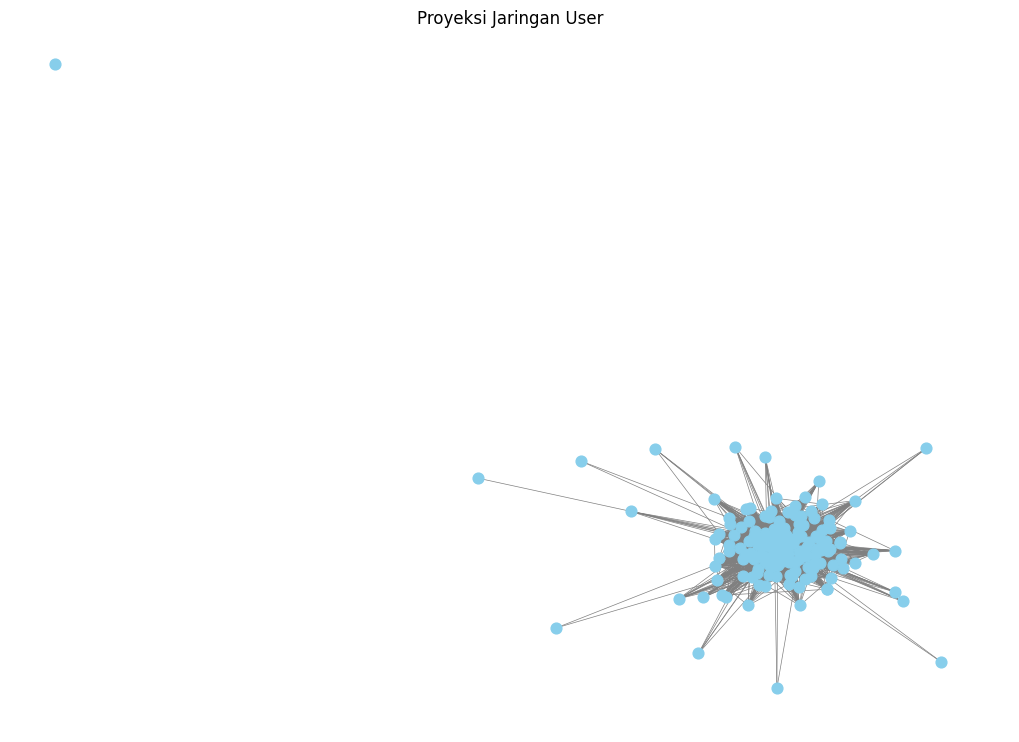

VSM User dibuat dengan menjadikan Visitor sebagai baris dan Item sebagai kolom. Nilai pada matriks menunjukkan jumlah interaksi antara Visitor dan Item.

Untuk mengurangi beban komputasi, kode mengambil 200 Visitor dengan jumlah interaksi tertinggi.

Karakteristik matriks VSM User:

| Karakteristik | Nilai |
|---|---:|
| Shape | (200, 22479) |
| Jumlah User | 200 |
| Jumlah Item | 22.479 |
| Nilai nonzero | 43.319 |
| Jumlah edge proyeksi User | 9.202 |

Proyeksi User dibuat menggunakan NetworkX. Dua User akan terhubung apabila keduanya pernah berinteraksi dengan Item yang sama. Bobot edge menunjukkan jumlah Item yang sama-sama diinteraksikan.

Graf divisualisasikan menggunakan `spring_layout` dengan seed 42 agar posisi simpul dapat direproduksi.

## 5. VSM terhadap Simpul Item

**Jawaban:**
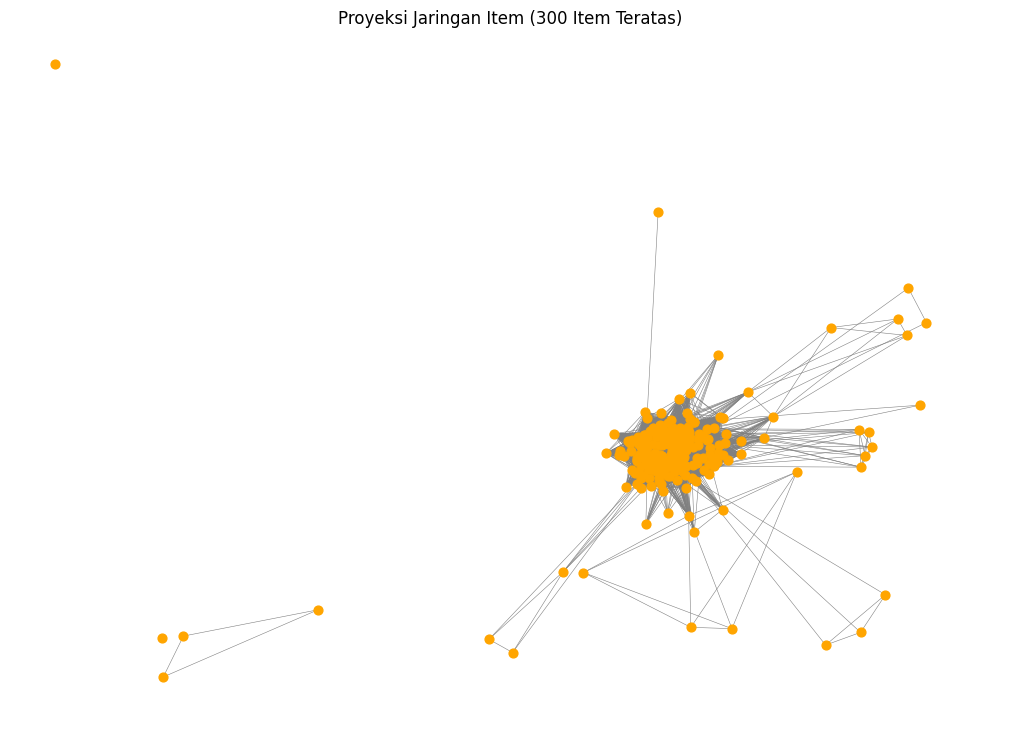

VSM Item dibuat dengan mentransposisi matriks VSM User. Pada matriks ini, Item menjadi baris dan User menjadi kolom.

Karakteristik matriks VSM Item:

| Karakteristik | Nilai |
|---|---:|
| Shape | (22479, 200) |
| Jumlah Item | 22.479 |
| Jumlah User | 200 |
| Nilai nonzero | 43.319 |

Proyeksi Item dibuat dengan memilih 300 Item dengan jumlah interaksi tertinggi. Dua Item akan terhubung apabila keduanya pernah diinteraksikan oleh User yang sama.

Hasil proyeksi memiliki 300 simpul dan 26.620 edge. Proyeksi ini dapat digunakan untuk melihat hubungan antar-Item berdasarkan pola interaksi User.

## 6. Perbandingan Proyeksi User dan Item

**Jawaban:**

Berdasarkan pengujian menggunakan 100 User dan 300 Item, diperoleh hasil berikut.

| Karakteristik | Proyeksi User | Proyeksi Item |
|---|---:|---:|
| Jumlah simpul | 100 | 100 |
| Jumlah edge | 2.741 | 3.474 |
| Kepadatan graf | 0,55374 | 0,70182 |
| Rata-rata derajat | 54,82 | 69,48 |
| Waktu pembentukan | 0,02891 detik | 0,02754 detik |

Berdasarkan hasil pengujian pada 100 User dan 100 Item, proyeksi Item menghasilkan jumlah edge dan kepadatan graf yang lebih tinggi dibandingkan proyeksi User. Waktu pembentukan proyeksi Item juga sedikit lebih singkat pada pengukuran ini. Namun, satu kali pengukuran belum cukup untuk menyimpulkan bahwa proyeksi Item secara umum lebih efisien.

Pemilihan proyeksi perlu disesuaikan dengan tujuan analisis. Proyeksi User lebih sesuai untuk mempelajari kemiripan pola interaksi antar-Visitor, sedangkan proyeksi Item lebih sesuai untuk mempelajari keterkaitan antar-Item berdasarkan interaksi pengguna.

## 7. Menghitung Similarity pada Graf Terproyeksi

**Jawaban:**
![alt text](<similarity pada Neo4j.svg>)

Similarity dihitung menggunakan Jaccard Similarity berdasarkan kesamaan Item yang diinteraksikan oleh setiap pasangan Visitor.

Kode mengambil 300 Visitor dengan jumlah Item terbanyak, kemudian menghitung similarity setiap pasangan Visitor dan mengurutkan hasilnya dari nilai tertinggi.

### (a) Lima Pasangan dengan Similarity Tertinggi
Nilai similarity disimpan sebagai properti pada relasi `SIMILAR_TO` menggunakan query berikut.

```cypher
UNWIND $pairs AS pair
MATCH (a:Visitor {visitorId: pair.visitor_a})
MATCH (b:Visitor {visitorId: pair.visitor_b})
MERGE (a)-[r:SIMILAR_TO]-(b)
SET r.similarity = pair.similarity;
```

Query untuk menampilkan lima similarity tertinggi:

```cypher
MATCH (a:Visitor)-[r:SIMILAR_TO]-(b:Visitor)
RETURN
    a.visitorId AS visitor_a,
    b.visitorId AS visitor_b,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5;
```

### (b) Menyimpan Similarity ke Graf Neo4j

| No. | Visitor A | Visitor B | Similarity |
|---:|---:|---:|---:|
| 1 | 317355 | 360921 | 0,213542 |
| 2 | 1119917 | 917504 | 0,169935 |
| 3 | 518659 | 1000306 | 0,155056 |
| 4 | 856874 | 590943 | 0,146739 |
| 5 | 1119917 | 468309 | 0,138264 |

Pasangan Visitor 317355 dan 360921 memiliki similarity tertinggi sebesar 0,213542. Artinya, kedua Visitor tersebut memiliki kemiripan pola interaksi yang paling tinggi di antara pasangan yang diuji.


## 8. Kondisi Graf Sebelum dan Sesudah Similarity

**Jawaban:**

### Sebelum

Sebelum similarity dihitung, graf hanya menampilkan hubungan interaksi antara Visitor dan Item.

```cypher
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v, r, i
LIMIT 100;
```
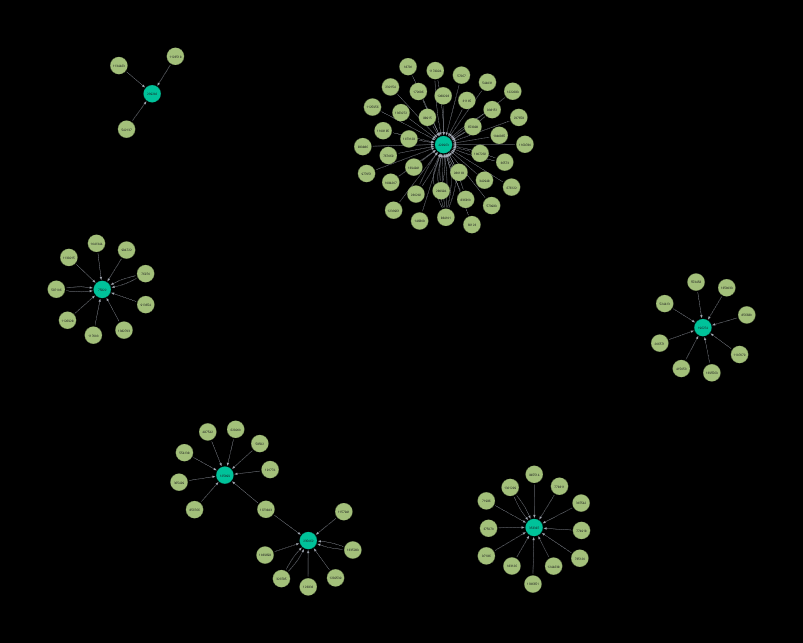

### Sesudah

Setelah similarity dihitung, graf memiliki relasi tambahan `SIMILAR_TO` yang menghubungkan Visitor dengan pola interaksi serupa.

```cypher
MATCH (a:Visitor)-[r:SIMILAR_TO]-(b:Visitor)
RETURN a, r, b
LIMIT 100;
```
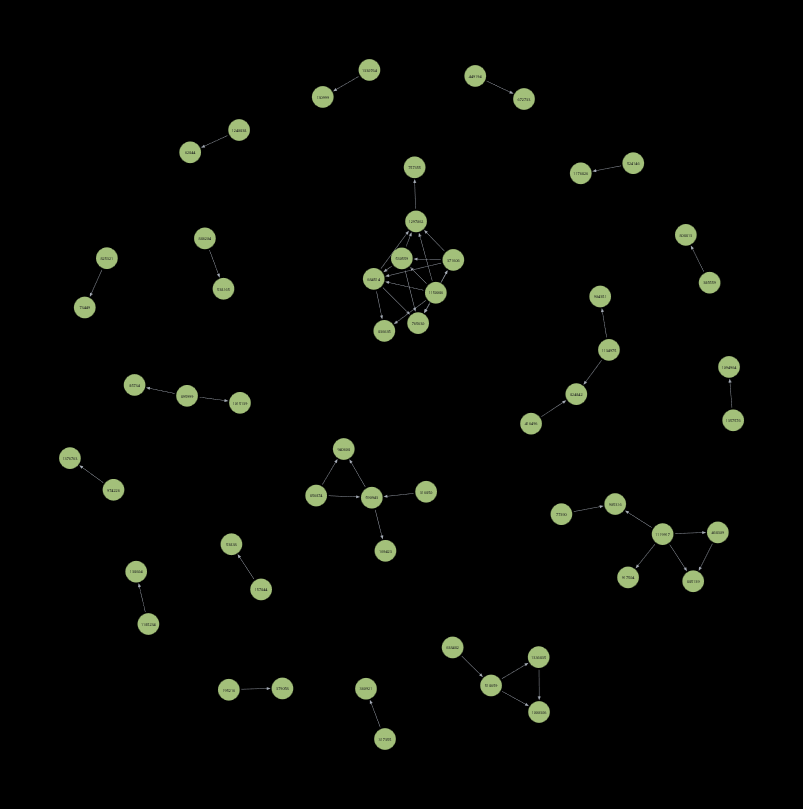
Penambahan relasi tersebut membuat graf dapat digunakan untuk melihat kemiripan antar-Visitor, selain hubungan interaksi Visitor dengan Item.


# B. Analytics

## 1. Rekomendasi Menggunakan KNN dengan K = 5

**Jawaban:**

Model KNN digunakan untuk mencari lima Visitor yang memiliki pola interaksi paling mirip dengan User target. Data P1 digunakan untuk membangun matriks interaksi dan melatih model, sedangkan data P2 digunakan untuk menguji hasil rekomendasi.

Pemilihan User dilakukan secara acak menggunakan seed 42 agar hasil pemilihan dapat direproduksi.

### (a) Skrip Python KNN

```python
from sklearn.neighbors import NearestNeighbors

K = 5

knn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

# Melatih model menggunakan data P1
knn.fit(user_item_matrix)

# Mencari tetangga terdekat User target
distances, neighbors = knn.kneighbors(
    user_item_matrix[uidx],
    return_distance=True
)
```

Setelah tetangga ditemukan, skor rekomendasi dihitung berdasarkan interaksi tetangga dan tingkat kemiripannya. Item yang sudah diinteraksikan oleh User pada P1 tidak direkomendasikan kembali.

### (b) Tiga Item Rekomendasi

Berdasarkan output notebook yang tersedia, User yang muncul pada baris pertama evaluasi adalah `428868`.

Tiga rekomendasi teratas untuk User tersebut adalah:

1. Item `248450`
2. Item `344723`
3. Item `259571`

Dua rekomendasi berikutnya pada Top-5 adalah Item `20968` dan `23477`.

Catatan: hasil tersebut merupakan rekomendasi untuk User `428868`, bukan User `1150086`.

## 2. Evaluasi Rekomendasi dengan Hit@5 dan NDCG@5

**Jawaban:**

Evaluasi dilakukan dengan membandingkan lima rekomendasi teratas dengan interaksi aktual pada data P2.

Berdasarkan output notebook terakhir, hasil evaluasinya adalah:

| Metrik | Nilai |
|---|---:|
| Hit@5 rata-rata | 0,0000 |
| NDCG@5 rata-rata | 0,0000 |
| Jumlah User yang dievaluasi | 26 |

### (a) Hit@5

Hit@5 digunakan untuk mengetahui apakah setidaknya satu dari lima Item yang direkomendasikan sesuai dengan Item yang diinteraksikan oleh User pada P2.

Nilai Hit@5 rata-rata sebesar 0,0000 menunjukkan bahwa tidak ada Item relevan yang ditemukan dalam lima rekomendasi teratas untuk User yang dievaluasi pada output tersebut.

### (b) NDCG@5

NDCG@5 digunakan untuk menilai kualitas urutan rekomendasi dengan memperhatikan posisi Item yang relevan. Item relevan yang muncul pada posisi lebih tinggi akan memberikan nilai yang lebih baik.

Nilai NDCG@5 rata-rata sebesar 0,0000 menunjukkan bahwa tidak ada Item relevan yang ditemukan pada Top-5 dalam hasil evaluasi tersebut.

Hasil evaluasi ini diperoleh dari 26 user yang memenuhi kriteria pengujian. Nilai Hit@5 dan NDCG@5 sebesar 0,0000 menunjukkan bahwa sistem belum berhasil menghasilkan rekomendasi relevan pada lima posisi teratas untuk user yang dievaluasi. Hasil ini terbatas pada sampel dan konfigurasi pengujian yang digunakan, sehingga belum dapat digeneralisasi ke seluruh dataset.